# Company Bankruptcy Prediction
#### 資料介紹

資料來源：Kaggle - Company Bankruptcy Prediction

資料規模：6,819 筆

特徵數量：每一欄皆為數值型指標，共95個欄位特徵

欄位說明：包含是否破產（Bankrupt?）與財務指標

#### 專案研究目標：
1. 尋找出導致破產的關鍵財務特徵
2. 尋找出最適模型
3. 研究步驟（數據不平衡與特徵選取）對模型分析重要性

#### 專案流程：
0.  引入必要套件
1.  載入資料
2.  檢查缺失值（含空白字串）與資料分割
3.  KNN 補值
4.  Scaling
5.  SMOTE + ENN
6.  繪製相關係數熱圖（篩選前）
7.  特徵選取（LASSO）
8.  繪製最終特徵相關係數熱圖
9.  顯示最終資料形狀與前五筆
10. 交叉驗證+搜尋超參數函式
11. 模型分析
12. Feature Importance
13. 圖示化結果
14. Top10 Feature Importance
15. 消融實驗


### 0. 引入必要套件

In [1]:
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from imblearn.combine import SMOTEENN
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from matplotlib_venn import venn3

### 1. 載入資料

In [2]:
data = pd.read_csv('/Users/zhihong/Desktop/Company Bankruptcy Prediction/bankruptcy.csv')
data

,Unnamed: 0,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,NaN,0.564050,1.0,0.016469
1,1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1.0,0.020794
2,2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1.0,0.016474
3,3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1.0,0.023982
4,4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,...,NaN,0.003878,NaN,0.598782,0.839973,0.278514,0.024752,0.575617,1.0,0.035490
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6814,6814,0,0.493687,0.539468,0.543230,0.604455,0.604462,0.998992,0.797409,0.809331,...,0.799927,0.000466,0.623620,0.604455,0.840359,0.279606,0.027064,0.566193,1.0,0.029890
6815,6815,0,0.475162,0.538269,0.524172,0.598308,0.598308,0.998992,0.797414,0.809327,...,0.799748,0.001959,0.623931,0.598306,0.840306,0.278132,0.027009,0.566018,1.0,0.038284
6816,6816,0,0.472725,0.533744,0.520638,0.610444,0.610213,0.998984,0.797401,0.809317,...,0.797778,0.002840,0.624156,0.610441,0.840138,0.275789,0.026791,0.565158,1.0,0.097649
6817,6817,0,0.506264,0.559911,0.554045,0.607850,0.607850,0.999074,0.797500,0.809399,...,0.811808,0.002837,0.623957,0.607846,0.841084,0.277547,0.026822,0.565302,1.0,0.044009


### 2. 檢查缺失值（含空白字串）與資料分割

將空白或只有空白的字串視為 NaN

In [3]:
data.replace(r'^\s*$', np.nan, regex = True, inplace = True)
print(f'各欄位缺失值數量：\n{data.isnull().sum()}')

各欄位缺失值數量：
Unnamed: 0                                                    0
Bankrupt?                                                     0
 ROA(C) before interest and depreciation before interest     98
 ROA(A) before interest and % after tax                     100
 ROA(B) before interest and depreciation after tax           98
                                                           ... 
 Liability to Equity                                        100
 Degree of Financial Leverage (DFL)                          99
 Interest Coverage Ratio (Interest expense to EBIT)          99
 Net Income Flag                                            100
 Equity to Liability                                        100
Length: 97, dtype: int64


分別 X, y

In [4]:
data = data.drop(columns = ["Unnamed: 0"])
X = data.drop('Bankrupt?', axis = 1)
y = data['Bankrupt?']
X_cols = X.columns
print(f'原始資料形狀：{X.shape}')
print(f'原始 y 類別分佈（比數）：\n{y.value_counts()}')
print(f'原始 y 類別分佈（比例）：\n{y.value_counts(normalize = True)}')

原始資料形狀：(6819, 95)
原始 y 類別分佈（比數）：
Bankrupt?
0    6599
1     220
Name: count, dtype: int64
原始 y 類別分佈（比例）：
Bankrupt?
0    0.967737
1    0.032263
Name: proportion, dtype: float64


Train / Test split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42, stratify = y)
print(f"Train y 類別分佈（筆數）：\n{y_train.value_counts()}")
print(f"Train y 類別分佈（比例）：\n{y_train.value_counts(normalize = True)}")

Train y 類別分佈（筆數）：
Bankrupt?
0    4619
1     154
Name: count, dtype: int64
Train y 類別分佈（比例）：
Bankrupt?
0    0.967735
1    0.032265
Name: proportion, dtype: float64


Bankrupt? (Before resampling)

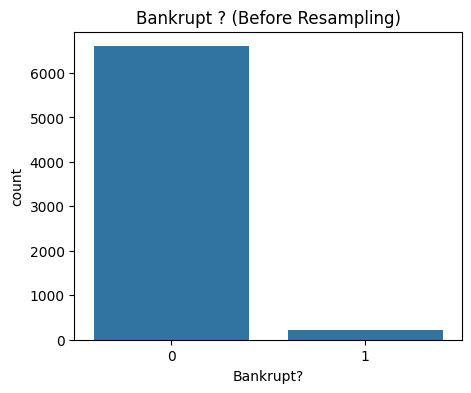

In [6]:
plt.figure(figsize = (5, 4))
sns.countplot(x = y)
plt.title('Bankrupt ? (Before Resampling)')
plt.show()

### 3. KNN 補值

In [7]:
imputer = KNNImputer(n_neighbors = 5)
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)
X_train_imputed = pd.DataFrame(X_train_imputed, columns = X_cols, index = X_train.index)
X_test_imputed = pd.DataFrame(X_test_imputed, columns = X_cols, index = X_test.index)
print(f"KNN 補值後 train 缺失值數量：\n{X_train_imputed.isnull().sum()}")
print(f"KNN 補值後 test 缺失值數量：\n{X_test_imputed.isnull().sum()}")

KNN 補值後 train 缺失值數量：
ROA(C) before interest and depreciation before interest    0
ROA(A) before interest and % after tax                     0
ROA(B) before interest and depreciation after tax          0
Operating Gross Margin                                     0
Realized Sales Gross Margin                                0
                                                          ..
Liability to Equity                                        0
Degree of Financial Leverage (DFL)                         0
Interest Coverage Ratio (Interest expense to EBIT)         0
Net Income Flag                                            0
Equity to Liability                                        0
Length: 95, dtype: int64
KNN 補值後 test 缺失值數量：
ROA(C) before interest and depreciation before interest    0
ROA(A) before interest and % after tax                     0
ROA(B) before interest and depreciation after tax          0
Operating Gross Margin                                     0
Realized Sales Gros

### 4. Scaling

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)
X_train_scaled = pd.DataFrame(X_train_scaled, columns = X_cols, index = X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns = X_cols, index = X_test.index)
print(f'Scaling 後 Train 形狀：{X_train_scaled.shape}')
print(f'Scaling 後 Test 形狀：{X_test_scaled.shape}')

Scaling 後 Train 形狀：(4773, 95)
Scaling 後 Test 形狀：(2046, 95)


### 5. 數據不平衡處理（SMOTE+ENN）

In [9]:
smote_enn = SMOTEENN(random_state = 42)
X_train_resample, y_train_resample = smote_enn.fit_resample(X_train_scaled, y_train)
X_train_resample = pd.DataFrame(X_train_resample, columns = X_cols)
y_train_resample = pd.Series(y_train_resample, name = 'Bankrupt?')
print(f"SMOTE+ENN 後 Train 形狀：{X_train_resample.shape}")
print(f"SMOTE+ENN 後 y_train 類別分佈（筆數）：\n{y_train_resample.value_counts()}")
print(f"SMOTE+ENN 後 y_train 類別分佈（比例）：\n{y_train_resample.value_counts(normalize = True)}")

SMOTE+ENN 後 Train 形狀：(8644, 95)
SMOTE+ENN 後 y_train 類別分佈（筆數）：
Bankrupt?
1    4614
0    4030
Name: count, dtype: int64
SMOTE+ENN 後 y_train 類別分佈（比例）：
Bankrupt?
1    0.533781
0    0.466219
Name: proportion, dtype: float64


Bankrupt? (After resampling)

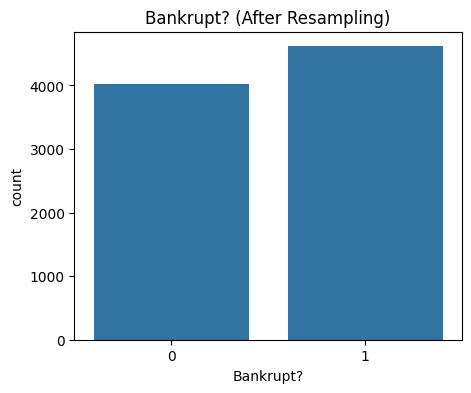

In [10]:
plt.figure(figsize = (5, 4))
sns.countplot(x = y_train_resample)
plt.title('Bankrupt? (After Resampling)')
plt.show()

### 6. 繪製相關係數熱圖（篩選前，使用 SMOTE+ENN 後的 X_resample）

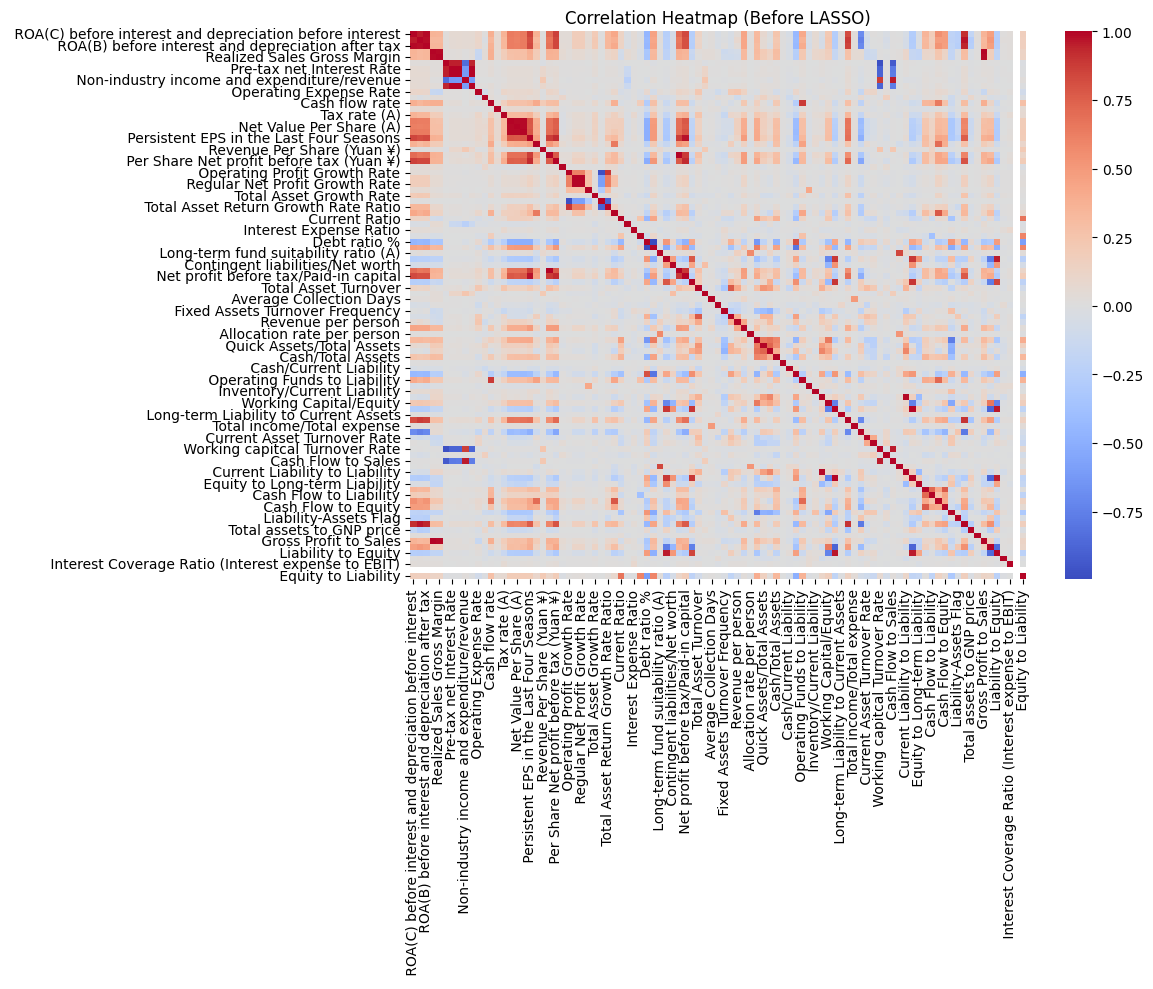

In [11]:
corr_before = X_train_resample.corr()
plt.figure(figsize = (12, 10))
sns.heatmap(corr_before, cmap = 'coolwarm', center = 0)
plt.title('Correlation Heatmap (Before LASSO)')
plt.tight_layout()
plt.show()

### 7. 特徵選取（LASSO）

In [12]:
X_lasso = X_train_resample.copy()
y_lasso = y_train_resample.copy()

尋找最適 C

In [13]:
C_list = [0.01, 0.05, 0.1, 0.5, 1]
eps = 1e-6

for C_val in C_list:
    clf_tmp = LogisticRegression(solver="saga", C=C_val, l1_ratio=1.0, max_iter=20000, tol=1e-4, random_state=42)
    clf_tmp.fit(X_lasso, y_lasso)
    n_nonzero = np.sum(np.abs(clf_tmp.coef_[0]) > eps)
    print(f"C = {C_val}, |coef|>{eps} 的特徵數 = {n_nonzero}")

C = 0.01, |coef|>1e-06 的特徵數 = 22
C = 0.05, |coef|>1e-06 的特徵數 = 46
C = 0.1, |coef|>1e-06 的特徵數 = 61
C = 0.5, |coef|>1e-06 的特徵數 = 78
C = 1, |coef|>1e-06 的特徵數 = 82


In [14]:
best_C = 0.01
lasso_clf = LogisticRegression(solver="saga", C=best_C, l1_ratio=1.0, max_iter=20000, tol=1e-4, random_state=42)
lasso_clf.fit(X_lasso, y_lasso)
coef = lasso_clf.coef_[0]
lasso_df = pd.DataFrame({"Feature": X_cols, "Coefficient": coef})
lasso_df["abs_coef"] = lasso_df["Coefficient"].abs()
lasso_df = lasso_df.sort_values(by="abs_coef", ascending=False)
print(lasso_df.head(30))

                                              Feature  Coefficient  abs_coef
37                                   Net worth/Assets    -1.222306  1.222306
18            Persistent EPS in the Last Four Seasons    -0.512656  0.512656
85                         Net Income to Total Assets    -0.463171  0.463171
56                                  Cash/Total Assets    -0.426352  0.426352
0    ROA(C) before interest and depreciation befor...    -0.424912  0.424912
36                                       Debt ratio %     0.377238  0.377238
42              Net profit before tax/Paid-in capital    -0.336701  0.336701
73                                 Cash Turnover Rate    -0.316483  0.316483
44                               Total Asset Turnover    -0.251163  0.251163
2    ROA(B) before interest and depreciation after...    -0.238159  0.238159
71                          Quick Asset Turnover Rate    -0.187181  0.187181
14                                       Tax rate (A)    -0.160548  0.160548

保留係數 ≠ 0 的特徵

In [15]:
selected_features = lasso_df[lasso_df['Coefficient'] != 0]['Feature'].tolist()
print(f"LASSO 最終選中的特徵數：{len(selected_features)}")
print("LASSO 最終選中的特徵：")
for feat in selected_features:
    print(f"- {feat}")
    
X_train_final = X_train_resample[selected_features].copy()
X_test_final = X_test_scaled[selected_features].copy()

LASSO 最終選中的特徵數：22
LASSO 最終選中的特徵：
-  Net worth/Assets
-  Persistent EPS in the Last Four Seasons
-  Net Income to Total Assets
-  Cash/Total Assets
-  ROA(C) before interest and depreciation before interest
-  Debt ratio %
-  Net profit before tax/Paid-in capital
-  Cash Turnover Rate
-  Total Asset Turnover
-  ROA(B) before interest and depreciation after tax
-  Quick Asset Turnover Rate
-  Tax rate (A)
-  Fixed Assets Turnover Frequency
-  Cash Flow to Liability
-  Total debt/Total net worth
-  Working Capital to Total Assets
-  Net Worth Turnover Rate (times)
-  Realized Sales Gross Profit Growth Rate
-  Inventory Turnover Rate (times)
-  Accounts Receivable Turnover
-  Continuous Net Profit Growth Rate
-  After-tax Net Profit Growth Rate


### 8. 繪製最終特徵相關係數熱圖（LASSO 後）

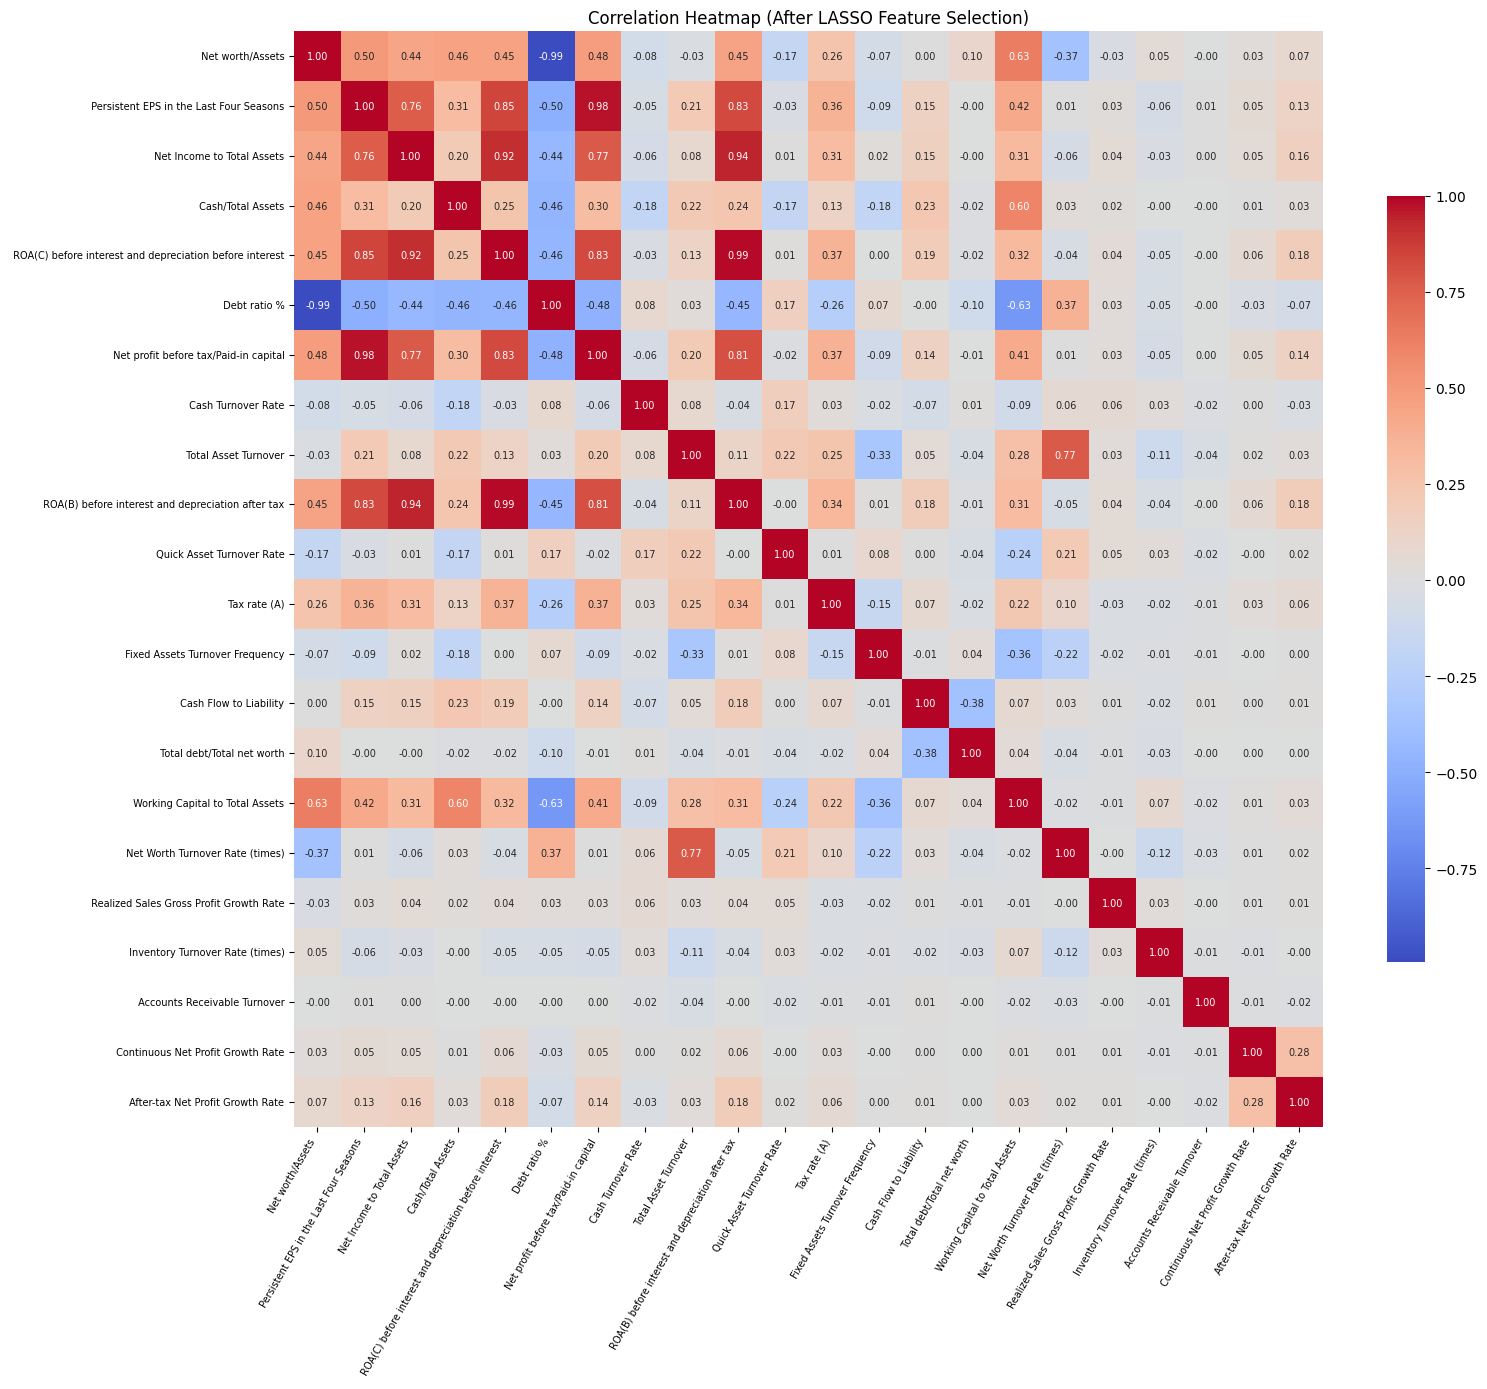

In [16]:
corr_after = X_train_final.corr()
plt.figure(figsize = (16,14))
sns.heatmap(corr_after, cmap = 'coolwarm', center = 0, fmt = '.2f', annot = True, annot_kws = {'size': 7}, cbar_kws = {'shrink': 0.7})
plt.title('Correlation Heatmap (After LASSO Feature Selection)')
plt.xticks(rotation = 60, ha = 'right', fontsize = 7)
plt.yticks(rotation = 0, fontsize = 7)
plt.tight_layout()
plt.show()

### 9. 顯示最終資料形狀與前五筆

In [17]:
print(f"最終特徵資料形狀：{X_train_final.shape}")
print(f"最終特徵資料前五筆：\n{X_train_final.head()}")

最終特徵資料形狀：(8644, 22)
最終特徵資料前五筆：
   Net worth/Assets  Persistent EPS in the Last Four Seasons  \
0          0.054451                                -0.238909   
1         -1.469452                                -0.250661   
2          0.435008                                 0.016694   
3          0.522743                                -0.391683   
4          1.662736                                -0.329986   

   Net Income to Total Assets  Cash/Total Assets  \
0                    0.059410          -0.832756   
1                   -0.169778          -0.747422   
2                    0.030008          -0.593323   
3                   -0.277644          -0.499460   
4                    0.163217          -0.649953   

   ROA(C) before interest and depreciation before interest  Debt ratio %  \
0                                           0.452524           -0.052986   
1                                          -0.587777            1.470588   
2                                          

### 10. 交叉驗證

In [18]:
X_train_0 = X_train_final.copy()
X_test_0 = X_test_final.copy()
y_train_0 = y_train_resample.copy()
y_test_0 = y_test.copy()

In [19]:
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)
    
    print(f"{model_name} 評估結果")
    print(f"Accuracy: {round(acc, 4)}")
    print(f"Recall: {round(recall, 4)}")
    print(f"Precision: {round(precision, 4)}")
    print(f"F1 Score: {round(f1, 4)}")
    print(f"AUC: {round(auc, 4)}")
    print(f"Confusion Matrix:\n{cm}")
    return model_name, acc, recall, precision, f1, auc

### 11. 模型分析
Logistic Regression

In [20]:
logit_best = LogisticRegression(solver="lbfgs", C=np.inf, max_iter=2000, random_state=42)
logit_best.fit(X_train_0, y_train_0)
logit_result = evaluate_model(logit_best, X_test_0, y_test_0, "Logistic Regression")


Logistic Regression 評估結果
Accuracy: 0.848
Recall: 0.8636
Precision: 0.1588
F1 Score: 0.2682
AUC: 0.9315
Confusion Matrix:
[[1678  302]
 [   9   57]]


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


Random Forest

In [21]:
rf = RandomForestClassifier(random_state = 42)
rf_param_grid = {'n_estimators': [100, 200, 300], 'max_depth': [None, 5, 10, 15], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'max_features': ["sqrt", "log2"]}
rf_grid = GridSearchCV(estimator = rf, param_grid = rf_param_grid, scoring = 'roc_auc', cv = cv, n_jobs = -1)
rf_grid.fit(X_train_0, y_train_0)
print(f"Random Forest 最佳參數：{rf_grid.best_params_}")
print(f"Random Forest 最佳 CV AUC：{rf_grid.best_score_:.4f}")
rf_best = rf_grid.best_estimator_
rf_result = evaluate_model(rf_best, X_test_0, y_test_0, 'Random Forest')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random Forest 最佳參數：{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Random Forest 最佳 CV AUC：0.9985
Random Forest 評估結果
Accuracy: 0.9267
Recall: 0.697
Precision: 0.2614
F1 Score: 0.3802
AUC: 0.9253
Confusion Matrix:
[[1850  130]
 [  20   46]]


XGBoost

In [22]:
xgb = XGBClassifier(objective = 'binary:logistic', eval_metric = 'logloss', n_jobs = -1, random_state = 42)
xgb_param_distributions = {
    'n_estimators': [100, 200, 300, 400],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.6, 0.8, 1],
    'colsample_bytree': [0.6, 0.8, 1],
    'gamma': [0, 1, 2],
    'min_child_weight': [1, 3, 5]}
xgb_random = RandomizedSearchCV(estimator = xgb, param_distributions = xgb_param_distributions,
                                n_iter = 30, scoring = 'roc_auc', cv = cv, random_state = 42, n_jobs = -1)
xgb_random.fit(X_train_0, y_train_0)
print(f'XGBoost最佳參數:{xgb_random.best_params_}')
print(f'XGBoost 最佳 CV AUC：{round(xgb_random.best_score_, 4)}')
xgb_best = xgb_random.best_estimator_
xgb_result = evaluate_model(xgb_best, X_test_0, y_test_0, 'XGBoost')

XGBoost最佳參數:{'subsample': 0.6, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.6}
XGBoost 最佳 CV AUC：0.998
XGBoost 評估結果
Accuracy: 0.9272
Recall: 0.7121
Precision: 0.2655
F1 Score: 0.3868
AUC: 0.9248
Confusion Matrix:
[[1850  130]
 [  19   47]]


### 12. Feature Importance
Logistic Regression

Logistic Regression Feature Importance (ranked by importance)
                                              Feature  Coefficient  abs_coef
0                                    Net worth/Assets    -2.360727  2.360727
6               Net profit before tax/Paid-in capital    -1.933766  1.933766
3                                   Cash/Total Assets    -1.472298  1.472298
16                    Net Worth Turnover Rate (times)    -1.448355  1.448355
19                       Accounts Receivable Turnover    -1.126273  1.126273
9    ROA(B) before interest and depreciation after...    -0.996362  0.996362
7                                  Cash Turnover Rate    -0.723229  0.723229
8                                Total Asset Turnover     0.626672  0.626672
13                             Cash Flow to Liability    -0.510212  0.510212
10                          Quick Asset Turnover Rate    -0.508398  0.508398
21                   After-tax Net Profit Growth Rate     0.336441  0.336441
18            

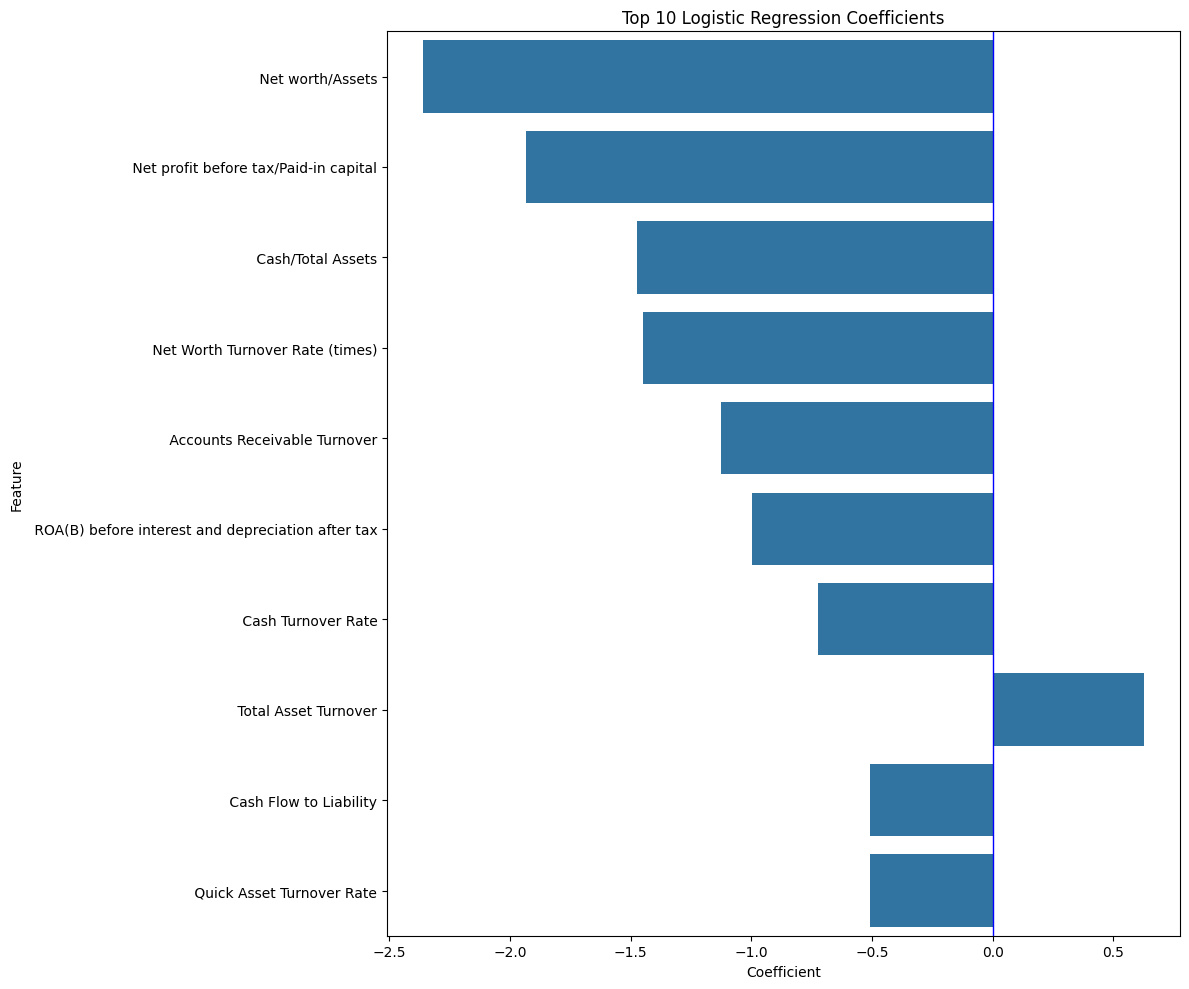

In [23]:
feature_names = X_train_0.columns
logit_coef = logit_best.coef_[0]
logit_coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': logit_coef})
logit_coef_df['abs_coef'] = logit_coef_df['Coefficient'].abs()
logit_coef_df = logit_coef_df.sort_values(by = 'abs_coef', ascending = False)
print(f'Logistic Regression Feature Importance (ranked by importance)\n{logit_coef_df.head(20)}')
plt.figure(figsize = (12, 10))
sns.barplot(data = logit_coef_df.head(10), x = 'Coefficient', y = 'Feature')
plt.title('Top 10 Logistic Regression Coefficients')
plt.axvline(0, c = 'b', linewidth = 1)
plt.tight_layout()
plt.show()

Random Forest

Random Forest Feature Importance (ranked by importance)
                                              Feature  Importance
1             Persistent EPS in the Last Four Seasons    0.141427
2                          Net Income to Total Assets    0.130337
5                                        Debt ratio %    0.107330
0                                    Net worth/Assets    0.094603
9    ROA(B) before interest and depreciation after...    0.089598
6               Net profit before tax/Paid-in capital    0.074068
4    ROA(C) before interest and depreciation befor...    0.072703
11                                       Tax rate (A)    0.034011
20                  Continuous Net Profit Growth Rate    0.031853
7                                  Cash Turnover Rate    0.028643
13                             Cash Flow to Liability    0.025957
15                    Working Capital to Total Assets    0.025753
3                                   Cash/Total Assets    0.024242
21                  

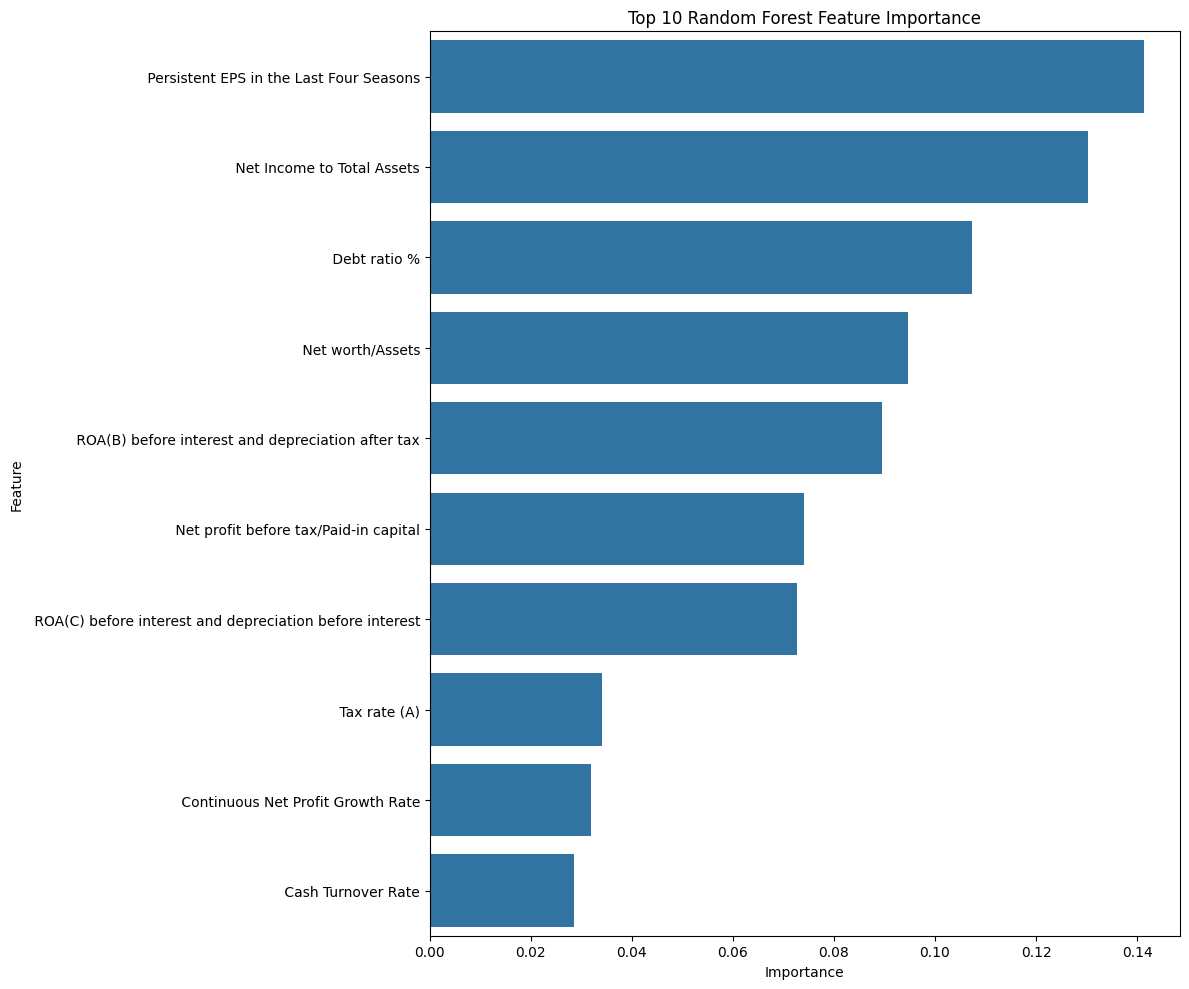

In [24]:
rf_importance = rf_best.feature_importances_
rf_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_importance}).sort_values(by = 'Importance', ascending = False)
print(f'Random Forest Feature Importance (ranked by importance)\n{rf_importance_df.head(20)}')
plt.figure(figsize = (12, 10))
sns.barplot(data = rf_importance_df.head(10), x = 'Importance', y = 'Feature')
plt.title('Top 10 Random Forest Feature Importance')
plt.tight_layout()
plt.show()

XGBoost

XGBoost Feature Importance (ranked by importance)
                                              Feature  Importance
1             Persistent EPS in the Last Four Seasons    0.218021
2                          Net Income to Total Assets    0.150236
0                                    Net worth/Assets    0.085753
4    ROA(C) before interest and depreciation befor...    0.076106
14                         Total debt/Total net worth    0.060000
5                                        Debt ratio %    0.057707
6               Net profit before tax/Paid-in capital    0.039990
18                    Inventory Turnover Rate (times)    0.029382
7                                  Cash Turnover Rate    0.028869
9    ROA(B) before interest and depreciation after...    0.027275
12                    Fixed Assets Turnover Frequency    0.026854
3                                   Cash/Total Assets    0.026303
10                          Quick Asset Turnover Rate    0.023875
11                        

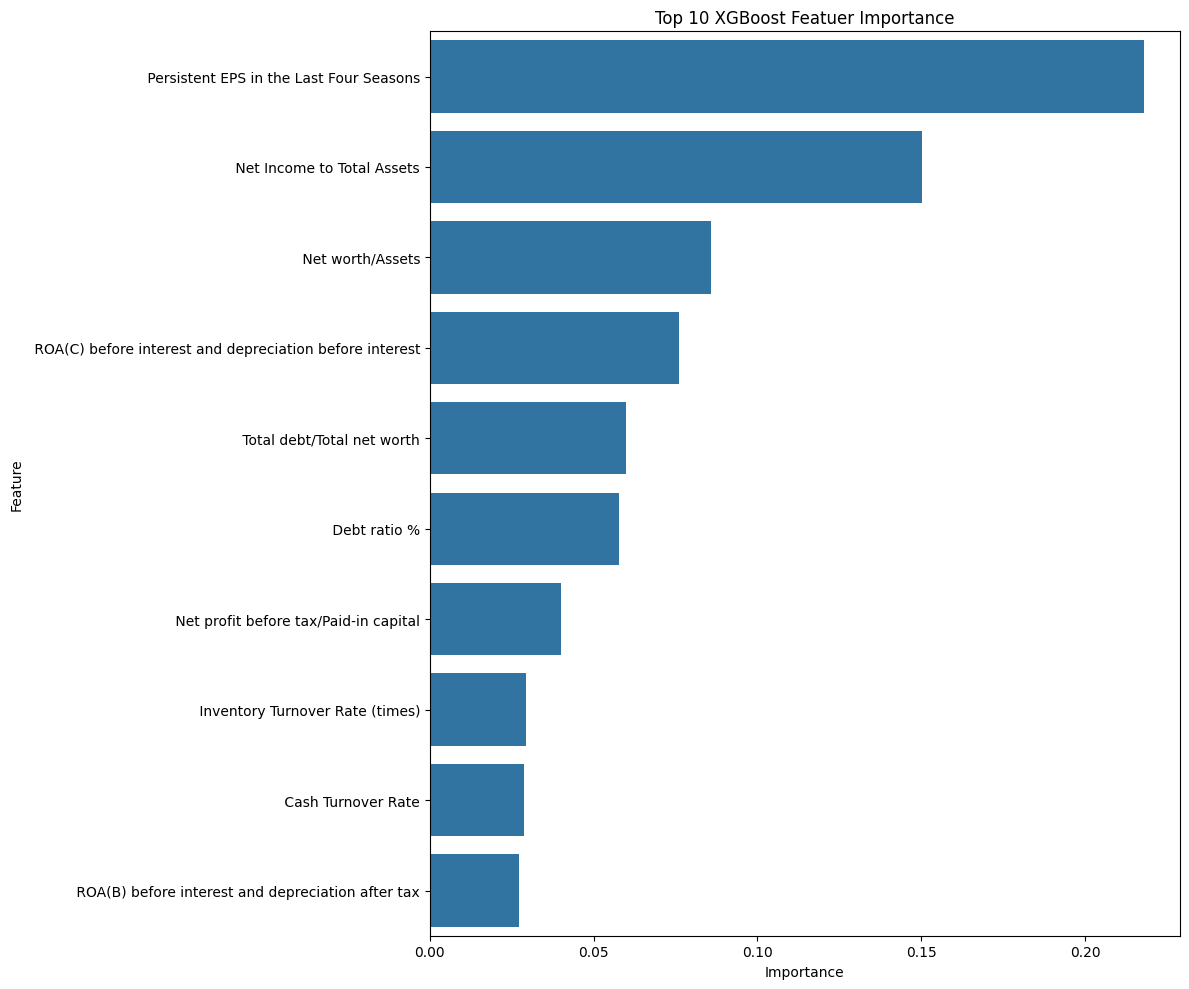

In [25]:
xgb_importance = xgb_best.feature_importances_
xgb_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_importance}).sort_values(by = 'Importance', ascending = False)
print(f'XGBoost Feature Importance (ranked by importance)\n{xgb_importance_df.head(20)}')
plt.figure(figsize = (12, 10))
sns.barplot(
    data = xgb_importance_df.head(10),
    x = 'Importance',
    y = 'Feature')
plt.title('Top 10 XGBoost Featuer Importance')
plt.tight_layout()
plt.show()

比較表格

In [26]:
def result_to_dict(result_tuple):
    return {
        'Model': result_tuple[0],
        'Accuracy': round(result_tuple[1], 4),
        'Recall': round(result_tuple[2], 4),
        'Precision': round(result_tuple[3], 4),
        'F1 Score': round(result_tuple[4], 4),
        'AUC': round(result_tuple[5], 4)}

In [27]:
results_list = [
    result_to_dict(logit_result),
    result_to_dict(rf_result),
    result_to_dict(xgb_result)]
results_df = pd.DataFrame(results_list)
print(f'三模型測試集比較\n{results_df}')

三模型測試集比較
                 Model  Accuracy  Recall  Precision  F1 Score     AUC
0  Logistic Regression    0.8480  0.8636     0.1588    0.2682  0.9315
1        Random Forest    0.9267  0.6970     0.2614    0.3802  0.9253
2              XGBoost    0.9272  0.7121     0.2655    0.3868  0.9248


### 13. 圖示化結果
三模型特徵重要性比較圖

/var/folders/8x/cx8m9rm94zzdnz5347dzf_v00000gn/T/ipykernel_5451/1923302847.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=logit_top10, x='Importance', y='Feature', palette='Blues_r')
/var/folders/8x/cx8m9rm94zzdnz5347dzf_v00000gn/T/ipykernel_5451/1923302847.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_top10, x='Importance', y='Feature', palette='Greens_r')
/var/folders/8x/cx8m9rm94zzdnz5347dzf_v00000gn/T/ipykernel_5451/1923302847.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_top10, x='Importance', y

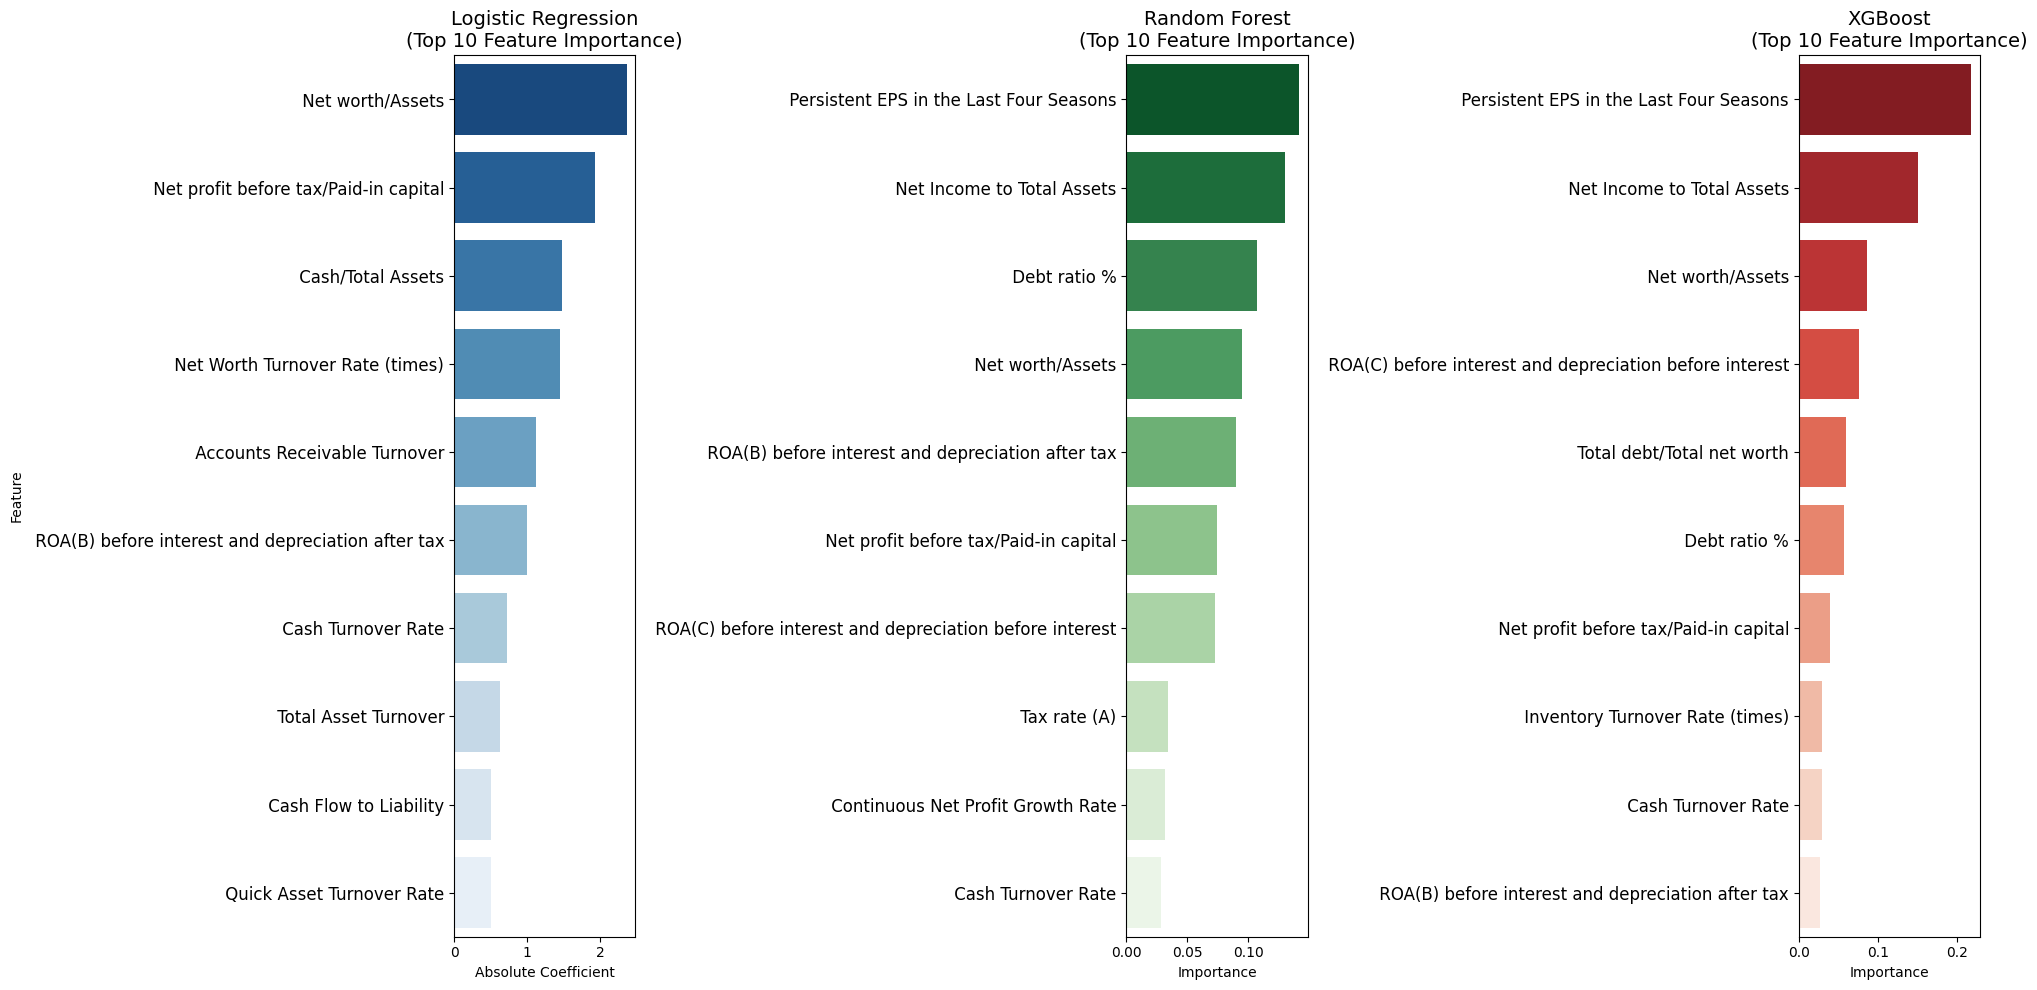

In [28]:
logit_df = logit_coef_df.copy()
logit_df = logit_df[['Feature', 'abs_coef']].rename(columns={'abs_coef': 'Importance'})
logit_top10 = logit_df.sort_values(by='Importance', ascending=False).head(10)

rf_df = rf_importance_df.copy()
rf_top10 = rf_df.sort_values(by='Importance', ascending=False).head(10)

xgb_df = xgb_importance_df.copy()
xgb_top10 = xgb_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(20, 10))
plt.subplot(1, 3, 1)
sns.barplot(data=logit_top10, x='Importance', y='Feature', palette='Blues_r')
plt.title('Logistic Regression\n(Top 10 Feature Importance)', fontsize=14)
plt.xlabel('Absolute Coefficient')
plt.ylabel('Feature')
plt.yticks(fontsize=12)

plt.subplot(1, 3, 2)
sns.barplot(data=rf_top10, x='Importance', y='Feature', palette='Greens_r')
plt.title('Random Forest\n(Top 10 Feature Importance)', fontsize=14)
plt.xlabel('Importance')
plt.ylabel('')
plt.yticks(fontsize=12)

plt.subplot(1, 3, 3)
sns.barplot(data=xgb_top10, x='Importance', y='Feature', palette='Reds_r')
plt.title('XGBoost\n(Top 10 Feature Importance)', fontsize=14)
plt.xlabel('Importance')
plt.ylabel('')
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()

三模型特徵 Top10 的 Venn Diagram

Logistic Regression Top10: {' Net profit before tax/Paid-in capital', ' Cash/Total Assets', ' Net Worth Turnover Rate (times)', ' Net worth/Assets', ' Accounts Receivable Turnover', ' Cash Flow to Liability', ' ROA(B) before interest and depreciation after tax', ' Quick Asset Turnover Rate', ' Total Asset Turnover', ' Cash Turnover Rate'}
Random Forest Top10: {' Net profit before tax/Paid-in capital', ' Net worth/Assets', ' Net Income to Total Assets', ' ROA(B) before interest and depreciation after tax', ' Persistent EPS in the Last Four Seasons', ' Debt ratio %', ' Continuous Net Profit Growth Rate', ' Tax rate (A)', ' ROA(C) before interest and depreciation before interest', ' Cash Turnover Rate'}
XGBoost Top10: {' Net profit before tax/Paid-in capital', ' Inventory Turnover Rate (times)', ' Net worth/Assets', ' Net Income to Total Assets', ' Total debt/Total net worth', ' Persistent EPS in the Last Four Seasons', ' ROA(B) before interest and depreciation after tax', ' Debt ratio %'

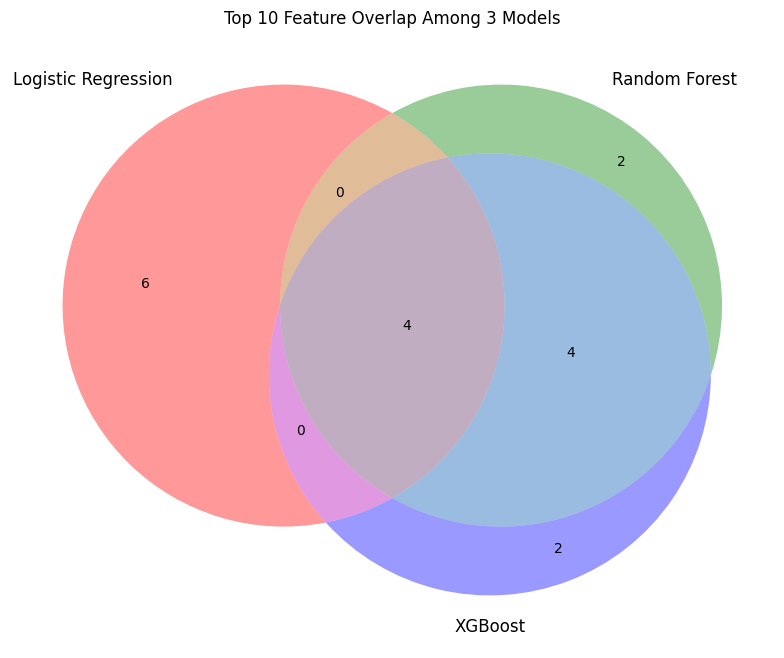

                             三模型共同特徵 (LR ∩ RF ∩ XGB)  \
0                                 Cash Turnover Rate   
1              Net profit before tax/Paid-in capital   
2                                   Net worth/Assets   
3  ROA(B) before interest and depreciation after tax   
4                                                      
5                                                      
6                                                      
7                                                      

                             Logistic ∩ RandomForest  \
0                                 Cash Turnover Rate   
1              Net profit before tax/Paid-in capital   
2                                   Net worth/Assets   
3  ROA(B) before interest and depreciation after tax   
4                                                      
5                                                      
6                                                      
7                                              

In [29]:
logit_features = set(logit_top10['Feature'])
rf_features = set(rf_top10['Feature'])
xgb_features = set(xgb_top10['Feature'])

print("Logistic Regression Top10:", logit_features)
print("Random Forest Top10:", rf_features)
print("XGBoost Top10:", xgb_features)

plt.figure(figsize=(10, 8))
venn = venn3(
    subsets=(logit_features, rf_features, xgb_features),
    set_labels=('Logistic Regression', 'Random Forest', 'XGBoost'))
plt.title("Top 10 Feature Overlap Among 3 Models")
plt.show()

common_all3 = logit_features & rf_features & xgb_features
common_logit_rf = logit_features & rf_features
common_logit_xgb = logit_features & xgb_features
common_rf_xgb = rf_features & xgb_features

def clean_and_sort(feature_set):
    clean = sorted({f.strip() for f in feature_set})
    return clean

result_dict = {
    "三模型共同特徵 (LR ∩ RF ∩ XGB)": clean_and_sort(common_all3),
    "Logistic ∩ RandomForest": clean_and_sort(common_logit_rf),
    "Logistic ∩ XGBoost": clean_and_sort(common_logit_xgb),
    "RandomForest ∩ XGBoost": clean_and_sort(common_rf_xgb)}

max_len = max(len(v) for v in result_dict.values())
df = pd.DataFrame({k: v + [""] * (max_len - len(v)) for k, v in result_dict.items()})
print(df)


set_logit = set(logit_top10['Feature'])
set_rf = set(rf_top10['Feature'])
set_xgb = set(xgb_top10['Feature'])

print("Logistic ∩ RF ∩ XGB:")
for i in set_logit & set_rf & set_xgb:
    print(i)

print('Logistic ∩ RF:')
for i in set_logit & set_rf:
    print(i)

print("Logistic ∩ XGB:")
for i in set_logit & set_xgb:
    print(i)

print("RF ∩ XGB:")
for i in set_rf & set_xgb:
    print(i)

### 14. Top10 Feature Importance

In [30]:
logit_top10 = set(logit_coef_df.head(10)['Feature'])
rf_top10 = set(rf_importance_df.head(10)['Feature'])
xgb_top10 = set(xgb_importance_df.head(10)['Feature'])
common_top10 = logit_top10 & rf_top10 & xgb_top10
print('三模型共同出現的Top10特徵:')
for i in common_top10:
    print(i)
    
common_at_least_2 = ((logit_top10 & rf_top10) | (logit_top10 & xgb_top10) | (rf_top10 & xgb_top10))
print('\n至少兩種模型共同重要的特徵:')
for i in common_at_least_2:
    print(i)

三模型共同出現的Top10特徵:
 Net profit before tax/Paid-in capital
 ROA(B) before interest and depreciation after tax
 Net worth/Assets
 Cash Turnover Rate

至少兩種模型共同重要的特徵:
 Net profit before tax/Paid-in capital
 Net worth/Assets
 Net Income to Total Assets
 ROA(B) before interest and depreciation after tax
 Persistent EPS in the Last Four Seasons
 Debt ratio %
 ROA(C) before interest and depreciation before interest
 Cash Turnover Rate


### 總結：
特徵重要性分析顯示，三模型共同納入 Top10 的變數主要來自獲利能力（ROA(B)、稅前淨利與股本比）、資本結構（淨值比）以及資金運用效率（現金週轉率），顯示企業是否具備穩定且足以支撐營運的獲利與資本緩衝，為破產風險之核心因素。進一步觀察至少兩種模型共同重視的特徵，可發現負債比率、資產報酬率、盈餘持續性與現金流相關指標亦具有顯著影響，反映高槓桿、獲利惡化與現金流不足將同步放大企業財務風險。整體而言，不同模型在關鍵財務因子上呈現高度一致性，顯示研究結果具備穩健性與合理的經濟意涵。

### 15. 消融實驗
評估前處理步驟對模型效能的實際貢獻與檢驗流程是否有「不必要或造成負面影響」的步驟
#### Case 1. Remove SMOTE+ENN（省略步驟5）

In [31]:
X_lasso = X_train_scaled.copy()
y_lasso = y_train.copy()

best_C= 0.01
lasso_clf = LogisticRegression(penalty = 'l1', solver = 'saga', C = best_C, max_iter = 2000, n_jobs = -1, random_state = 42)
lasso_clf.fit(X_lasso, y_lasso)

coef = lasso_clf.coef_[0]
lasso_df = pd.DataFrame({'Feature': X_cols, 'Coefficient': coef})
lasso_df['abs_coef'] = lasso_df['Coefficient'].abs()
lasso_df = lasso_df.sort_values(by = 'abs_coef', ascending = False)
print(f'LASSO特徵係數 (依重要性排序):\n{lasso_df}')

selected_features = lasso_df[lasso_df['Coefficient'] != 0]['Feature'].tolist()
print(f'LASSO最終選中的特徵數: {len(selected_features)}')
print(f'LASSO最終選中的特徵:\n{selected_features}')

X_train_final = X_train_scaled[selected_features].copy()
X_test_final = X_test_scaled[selected_features].copy()
print(f"最終特徵資料形狀：{X_train_final.shape}")
print(f"最終特徵資料前五筆：\n{X_train_final.head()}")

X_train_1 = X_train_final.copy()
X_test_1 = X_test_final.copy()
y_train_1 = y_train.copy()
y_test_1 = y_test.copy()

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


LASSO特徵係數 (依重要性排序):
                                              Feature  Coefficient  abs_coef
85                         Net Income to Total Assets    -0.288931  0.288931
37                                   Net worth/Assets    -0.205957  0.205957
2    ROA(B) before interest and depreciation after...    -0.193854  0.193854
36                                       Debt ratio %     0.167889  0.167889
0    ROA(C) before interest and depreciation befor...    -0.017711  0.017711
..                                                ...          ...       ...
29                              Net Value Growth Rate     0.000000  0.000000
28                            Total Asset Growth Rate     0.000000  0.000000
27                  Continuous Net Profit Growth Rate     0.000000  0.000000
26                     Regular Net Profit Growth Rate     0.000000  0.000000
94                                Equity to Liability     0.000000  0.000000

[95 rows x 3 columns]
LASSO最終選中的特徵數: 6
LASSO最終選中的特徵:
['

#### 模型分析

Logistic Regression

In [32]:
logit_best = LogisticRegression(solver="lbfgs", C=np.inf, max_iter=2000, random_state=42)
logit_best.fit(X_train_1, y_train_1)
logit_result_1 = evaluate_model(logit_best, X_test_1, y_test_1, "Logistic Regression")

Logistic Regression 評估結果
Accuracy: 0.9687
Recall: 0.1212
Precision: 0.5714
F1 Score: 0.2
AUC: 0.918
Confusion Matrix:
[[1974    6]
 [  58    8]]


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


Random Forest

In [33]:
rf = RandomForestClassifier(random_state = 42)
rf_param_grid = {'n_estimators': [100, 200, 300], 'max_depth': [None, 5, 10, 15], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'max_features': ["sqrt", "log2"]}
rf_grid = GridSearchCV(estimator = rf, param_grid = rf_param_grid, scoring = 'roc_auc', cv = cv, n_jobs = -1)
rf_grid.fit(X_train_1, y_train_1)
print(f"Random Forest 最佳參數：{rf_grid.best_params_}")
print(f"Random Forest 最佳 CV AUC：{rf_grid.best_score_:.4f}")
rf_best = rf_grid.best_estimator_
rf_result_1 = evaluate_model(rf_best, X_test_1, y_test_1, 'Random Forest')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random Forest 最佳參數：{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Random Forest 最佳 CV AUC：0.9188
Random Forest 評估結果
Accuracy: 0.9673
Recall: 0.0152
Precision: 0.3333
F1 Score: 0.029
AUC: 0.9147
Confusion Matrix:
[[1978    2]
 [  65    1]]


XGBoost

In [34]:
xgb = XGBClassifier(objective = 'binary:logistic', eval_metric = 'logloss', n_jobs = -1, random_state = 42)
xgb_param_distributions = {
    'n_estimators': [100, 200, 300, 400],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.6, 0.8, 1],
    'colsample_bytree': [0.6, 0.8, 1],
    'gamma': [0, 1, 2],
    'min_child_weight': [1, 3, 5]}
xgb_random = RandomizedSearchCV(estimator = xgb, param_distributions = xgb_param_distributions,
                                n_iter = 30, scoring = 'roc_auc', cv = cv, random_state = 42, n_jobs = -1)
xgb_random.fit(X_train_1, y_train_1)
print(f'XGBoost最佳參數:{xgb_random.best_params_}')
print(f'XGBoost 最佳 CV AUC：{round(xgb_random.best_score_, 4)}')
xgb_best = xgb_random.best_estimator_
xgb_result_1 = evaluate_model(xgb_best, X_test_1, y_test_1, 'XGBoost')

XGBoost最佳參數:{'subsample': 0.6, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 2, 'colsample_bytree': 0.8}
XGBoost 最佳 CV AUC：0.9214
XGBoost 評估結果
Accuracy: 0.9677
Recall: 0.0
Precision: 0.0
F1 Score: 0.0
AUC: 0.9187
Confusion Matrix:
[[1980    0]
 [  66    0]]


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


模型比較

In [35]:
results_list_1 = [
    result_to_dict(logit_result_1),
    result_to_dict(rf_result_1),
    result_to_dict(xgb_result_1)]
results_df_1 = pd.DataFrame(results_list_1)
print(f'Remove SMOTE+ENN 三模型測試集比較\n{results_df_1}')

Remove SMOTE+ENN 三模型測試集比較
                 Model  Accuracy  Recall  Precision  F1 Score     AUC
0  Logistic Regression    0.9687  0.1212     0.5714     0.200  0.9180
1        Random Forest    0.9673  0.0152     0.3333     0.029  0.9147
2              XGBoost    0.9677  0.0000     0.0000     0.000  0.9187


#### Case 2. Remove LASSO（省略步驟7）

In [36]:
X_train_2 = X_train_resample.copy()
X_test_2 = X_test_scaled.copy()
y_train_2 = y_train_resample.copy()
y_test_2 = y_test.copy()

#### 模型分析
Logistic Regression

In [37]:
logit_best = LogisticRegression(solver="lbfgs", C=np.inf, max_iter=2000, random_state=42)
logit_best.fit(X_train_2, y_train_2)
logit_result_2 = evaluate_model(logit_best, X_test_2, y_test_2, "Logistic Regression")

Logistic Regression 評估結果
Accuracy: 0.8666
Recall: 0.7576
Precision: 0.1629
F1 Score: 0.2681
AUC: 0.9125
Confusion Matrix:
[[1723  257]
 [  16   50]]


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1170: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


Random Forest

In [38]:
rf = RandomForestClassifier(random_state = 42)
rf_param_grid = {'n_estimators': [100, 200, 300], 'max_depth': [None, 5, 10, 15], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'max_features': ["sqrt", "log2"]}
rf_grid = GridSearchCV(estimator = rf, param_grid = rf_param_grid, scoring = 'roc_auc', cv = cv, n_jobs = -1)
rf_grid.fit(X_train_2, y_train_2)
print(f"Random Forest 最佳參數：{rf_grid.best_params_}")
print(f"Random Forest 最佳 CV AUC：{rf_grid.best_score_:.4f}")
rf_best = rf_grid.best_estimator_
rf_result_2 = evaluate_model(rf_best, X_test_2, y_test_2, 'Random Forest')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random Forest 最佳參數：{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Random Forest 最佳 CV AUC：0.9996
Random Forest 評估結果
Accuracy: 0.934
Recall: 0.6818
Precision: 0.283
F1 Score: 0.4
AUC: 0.9438
Confusion Matrix:
[[1866  114]
 [  21   45]]


XGBoost

In [39]:
xgb = XGBClassifier(objective = 'binary:logistic', eval_metric = 'logloss', n_jobs = -1, random_state = 42)
xgb_param_distributions = {
    'n_estimators': [100, 200, 300, 400],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.6, 0.8, 1],
    'colsample_bytree': [0.6, 0.8, 1],
    'gamma': [0, 1, 2],
    'min_child_weight': [1, 3, 5]}
xgb_random = RandomizedSearchCV(estimator = xgb, param_distributions = xgb_param_distributions,
                                n_iter = 30, scoring = 'roc_auc', cv = cv, random_state = 42, n_jobs = -1)
xgb_random.fit(X_train_2, y_train_2)
print(f'XGBoost最佳參數:{xgb_random.best_params_}')
print(f'XGBoost 最佳 CV AUC：{round(xgb_random.best_score_, 4)}')
xgb_best = xgb_random.best_estimator_
xgb_result_2 = evaluate_model(xgb_best, X_test_2, y_test_2, 'XGBoost')

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


XGBoost最佳參數:{'subsample': 0.6, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.6}
XGBoost 最佳 CV AUC：0.9996
XGBoost 評估結果
Accuracy: 0.9428
Recall: 0.6212
Precision: 0.3083
F1 Score: 0.4121
AUC: 0.9498
Confusion Matrix:
[[1888   92]
 [  25   41]]


模型比較

In [40]:
results_list_2 = [
    result_to_dict(logit_result_2),
    result_to_dict(rf_result_2),
    result_to_dict(xgb_result_2)]
results_df_2 = pd.DataFrame(results_list_2)
print(f'Remove LASSO 三模型測試集比較\n{results_df_2}')

Remove LASSO 三模型測試集比較
                 Model  Accuracy  Recall  Precision  F1 Score     AUC
0  Logistic Regression    0.8666  0.7576     0.1629    0.2681  0.9125
1        Random Forest    0.9340  0.6818     0.2830    0.4000  0.9438
2              XGBoost    0.9428  0.6212     0.3083    0.4121  0.9498


#### 3 個Case比較

In [41]:
dfs = []
results_list_full = [
    result_to_dict(logit_result),
    result_to_dict(rf_result),
    result_to_dict(xgb_result),
    result_to_dict(logit_result_1),
    result_to_dict(rf_result_1),
    result_to_dict(xgb_result_1),
    result_to_dict(logit_result_2),
    result_to_dict(rf_result_2),
    result_to_dict(xgb_result_2),
]

results_df_full = pd.DataFrame(results_list_full)

case_titles = [
    "Case 0. Complete Process",
    "Case 1. Remove SMOTE+ENN",
    "Case 2. Remove LASSO"
]

print("3 Cases Model Test Set Comparison\n")

case_size = 3
for case_id, i in enumerate(range(0, len(results_df_full), case_size)):
    case_df = results_df_full.iloc[i:i+case_size]

    title = case_titles[case_id] if case_id < len(case_titles) else f"Case {case_id}"
    print(title)
    print(case_df.to_string(index=False))
    print()

3 Cases Model Test Set Comparison

Case 0. Complete Process
              Model  Accuracy  Recall  Precision  F1 Score    AUC
Logistic Regression    0.8480  0.8636     0.1588    0.2682 0.9315
      Random Forest    0.9267  0.6970     0.2614    0.3802 0.9253
            XGBoost    0.9272  0.7121     0.2655    0.3868 0.9248

Case 1. Remove SMOTE+ENN
              Model  Accuracy  Recall  Precision  F1 Score    AUC
Logistic Regression    0.9687  0.1212     0.5714     0.200 0.9180
      Random Forest    0.9673  0.0152     0.3333     0.029 0.9147
            XGBoost    0.9677  0.0000     0.0000     0.000 0.9187

Case 2. Remove LASSO
              Model  Accuracy  Recall  Precision  F1 Score    AUC
Logistic Regression    0.8666  0.7576     0.1629    0.2681 0.9125
      Random Forest    0.9340  0.6818     0.2830    0.4000 0.9438
            XGBoost    0.9428  0.6212     0.3083    0.4121 0.9498



### 總結：
本研究以 Recall 作為主要評估指標，著重於模型辨識破產企業之能力。實證結果顯示，在高度不平衡的資料結構下，若未進行數據不平衡處理，模型 Recall 幾乎趨近於零，顯示無法有效捕捉破產樣本，實務應用價值有限。相較之下，SMOTE+ENN 能顯著改善模型對少數類別的學習效果，為提升破產辨識能力之關鍵步驟。此外，LASSO特徵選取可有效降低冗餘與雜訊變數，提升模型穩定性與整體預測表現。整體而言，SMOTE+ENN 與 LASSO 皆為必要流程，其中在資料嚴重不平衡的情境下，SMOTE+ENN 具有更為核心的重要性。